In [57]:
# 그래프관련 import 
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 프로그램 
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier # 분류 클래스
from sklearn.neighbors import KNeighborsRegressor # 예측 클래스
from sklearn.linear_model import LinearRegression # 예측 클래스
from sklearn.metrics import mean_absolute_error # 평균절대오차 오차범위 클래스
from sklearn.preprocessing import StandardScaler  # 정규화 클래스
from sklearn.model_selection import train_test_split

In [58]:
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
     21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
     22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
     27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
     36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
     40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
     )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
     110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
     130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
     197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
     514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
     820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
     1000.0, 1000.0]
     )

In [59]:
train_data,test_data,train_label,test_label = train_test_split(perch_length,perch_weight)
train_data

array([24. , 21.3, 32.8, 27.5, 35. , 43. , 24. , 15. , 37. , 37. , 19.6,
       27.5, 40. , 22. , 22. , 18. , 40. , 43. , 21. , 22. , 22. , 22.5,
       23.5, 39. ,  8.4, 13.7, 26.5, 21. , 40. , 20. , 27.3, 34.5, 39. ,
       18.7, 16.2, 28.7, 19. , 24.6, 25. , 22.7, 30. , 23. ])

In [60]:
train_data = train_data.reshape(-1,1)
test_data = test_data.reshape(-1,1)
train_data[:2]
test_data[:2]

array([[21.],
       [28.]])

In [61]:
# 데이터 전처리 - 다항회귀
# train_data[[ 43.5**2, 43.5]] # 항이 2개이다의 뜻, 항을 늘리면 정확도가 높아짐

train_poly = np.column_stack((train_data**2,train_data))
train_poly[:2] # 예측값 (y) = ax2 (2는 제곱근) + bx + 1 로 변경
test_poly = np.column_stack((test_data**2,test_data))
test_poly[:2]


array([[441.,  21.],
       [784.,  28.]])

In [62]:
# 데이터 학습 
lr = LinearRegression()
lr.fit(train_poly,train_label)

# 데이트 예측 
predict = lr.predict(test_poly)
print('무게 예측 :', predict)

# 정확도 
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print("train 정확도 :", score)
print("test 정확도 :", score2)


무게 예측 : [ 109.7306196   303.79802157 1145.30926687 1110.63175039  130.96656767
  142.39553751  822.86397643  286.4217491  1009.84318419  655.34866818
  883.02772351  681.91622653   51.18799413  225.32276824]
train 정확도 : 0.9683859204278361
test 정확도 : 0.9745972114220423


In [ ]:
in_data = 25
result = lr.predict([[in_data**2,in_data]])
print('예측무게 : ',result)

예측무게 :  [207.65034486]


In [64]:
print(lr.coef_,lr.intercept_)

[  1.08132775 -25.26114522] 163.34913109010617


In [65]:
print(lr.coef_[0])

1.0813277506504109


In [66]:
point = np.arange(15,50) # 1cm 씩 선을 긋겠다는 의미
point[:5]

array([15, 16, 17, 18, 19])

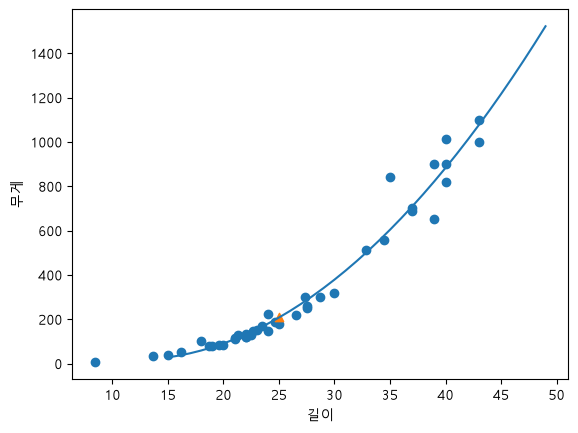

In [67]:
# 산점도 그래프 
# 딥러닝, 머신러닝에는 직선 외에는 그래프 진행이 안되기에 

plt.scatter(train_data,train_label)
plt.scatter(25,208.83, marker='^')
plt.plot(point,lr.coef_[0]*point**2+lr.coef_[1]*point+lr.intercept_)
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

In [68]:
data = np.column_stack((perch_length,perch_weight)) # 괄호 2개 
data[:2]

array([[ 8.4,  5.9],
       [13.7, 32. ]])